In [10]:
import geopandas as gpd  #this is 
import pandas as pd  
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

In [7]:
# Load Chicago city limits shapefile
# set to a common CRS (here im using 4326)
chicago_limits = gpd.read_file("../Chicago_City_Limits.shp").to_crs("EPSG:4326")
# example of 
chicago_roads = gpd.read_file("Chicago_PrimaryRoads.shp").to_crs("EPSG:4326")

In [19]:
chicago_communities = gpd.read_file("geo_export_10dd9ef8-bca3-4552-8cd7-62509747db53.shp").to_crs("EPSG:4326")

In [4]:
#making fake data you will replace with the open air data
data = pd.DataFrame({"lat": [41.88, 41.95, 41.78], "lon": [-87.63, -87.67, -87.60], "concentration": [12, 8, 22]})

<h1> Plot data

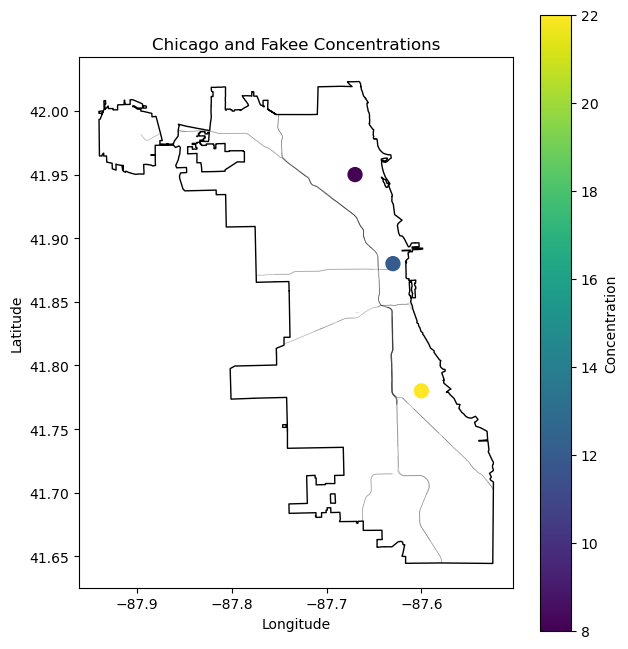

In [28]:
fig, ax = plt.subplots(figsize=(7, 8))

chicago_limits.plot(ax=ax, color="white", edgecolor="black")
chicago_roads.plot(ax=ax, color="k", alpha=0.2, linewidth=0.4)
dots = ax.scatter(data.lon, data.lat, c=data.concentration, cmap="viridis", s=100)

fig.colorbar(dots, ax=ax, label="Concentration")
ax.set_title("Chicago and Fakee Concentrations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

<h1> Plot data with discrete colorbar

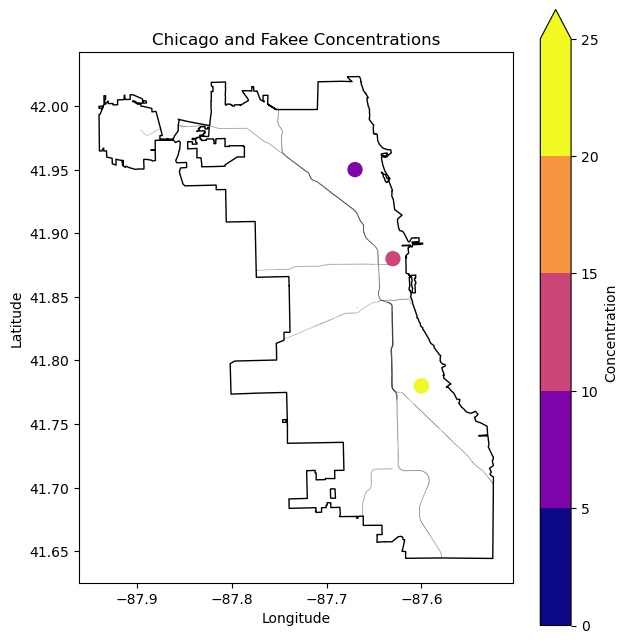

In [18]:
fig, ax = plt.subplots(figsize=(7, 8))

chicago_limits.plot(ax=ax, color="white", edgecolor="black")
chicago_roads.plot(ax=ax, color="k", alpha=0.2, linewidth=0.4)

# Choose the edges of the concentration groups
levels = [0, 5, 10, 15, 20, 25]

# give each group its own color
cmap = plt.get_cmap("plasma", len(levels) - 1)
norm = BoundaryNorm(levels, cmap.N)
dots = ax.scatter(data.lon, data.lat, c=data.concentration, cmap=cmap, norm=norm, s=100)

fig.colorbar(dots, ax=ax, boundaries=levels, ticks=levels, extend="max", label="Concentration")

ax.set_title("Chicago and Fakee Concentrations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

<h1> Plot with Chicago communitiy areas 

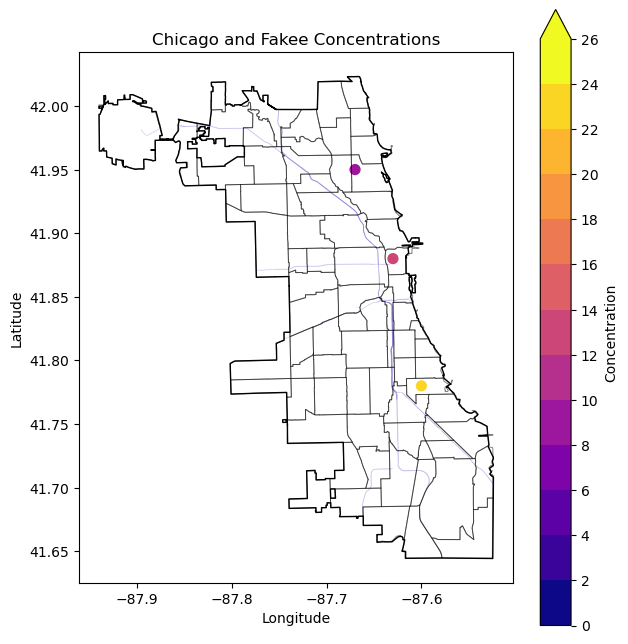

In [27]:
fig, ax = plt.subplots(figsize=(7, 8))

chicago_limits.plot(ax=ax, color="white", edgecolor="black")
chicago_roads.plot(ax=ax, color="slateblue", alpha=0.2, linewidth=0.4)
chicago_communities.boundary.plot(ax=ax, color="k", alpha=0.5, linewidth=0.7)

# Changed to have more discrete bins
levels = [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26]

# give each group its own color
cmap = plt.get_cmap("plasma", len(levels) - 1)
norm = BoundaryNorm(levels, cmap.N)

# You can change s to modify the size of teh dots.
dots = ax.scatter(data.lon, data.lat, c=data.concentration, cmap=cmap, norm=norm, s=50)

fig.colorbar(dots, ax=ax, boundaries=levels, ticks=levels, extend="max", label="Concentration")

ax.set_title("Chicago and Fakee Concentrations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

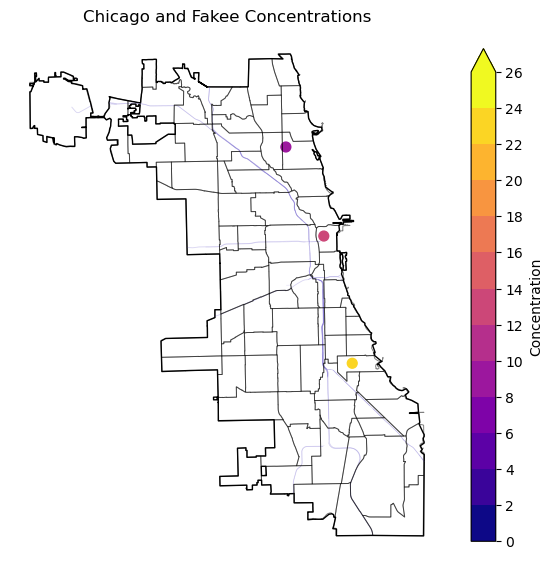

In [40]:
fig, ax = plt.subplots(figsize=(7, 8))

chicago_limits.plot(ax=ax, color="white", edgecolor="black")
chicago_roads.plot(ax=ax, color="slateblue", alpha=0.2, linewidth=0.4)
chicago_communities.boundary.plot(ax=ax, color="k", alpha=0.5, linewidth=0.7)

# Changed to have more discrete bins
levels = [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26]

# give each group its own color
cmap = plt.get_cmap("plasma", len(levels) - 1)
norm = BoundaryNorm(levels, cmap.N)

# You can change s to modify the size of teh dots.
dots = ax.scatter(data.lon, data.lat, c=data.concentration, cmap=cmap, norm=norm, s=50)

# shrink allows you to make the colorbar smaller. 
fig.colorbar(dots, ax=ax, boundaries=levels, ticks=levels, extend="max", label="Concentration", shrink=0.8)

ax.set_title("Chicago and Fakee Concentrations", )
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

#To remove the box around the plot
ax.set_axis_off()

plt.show()

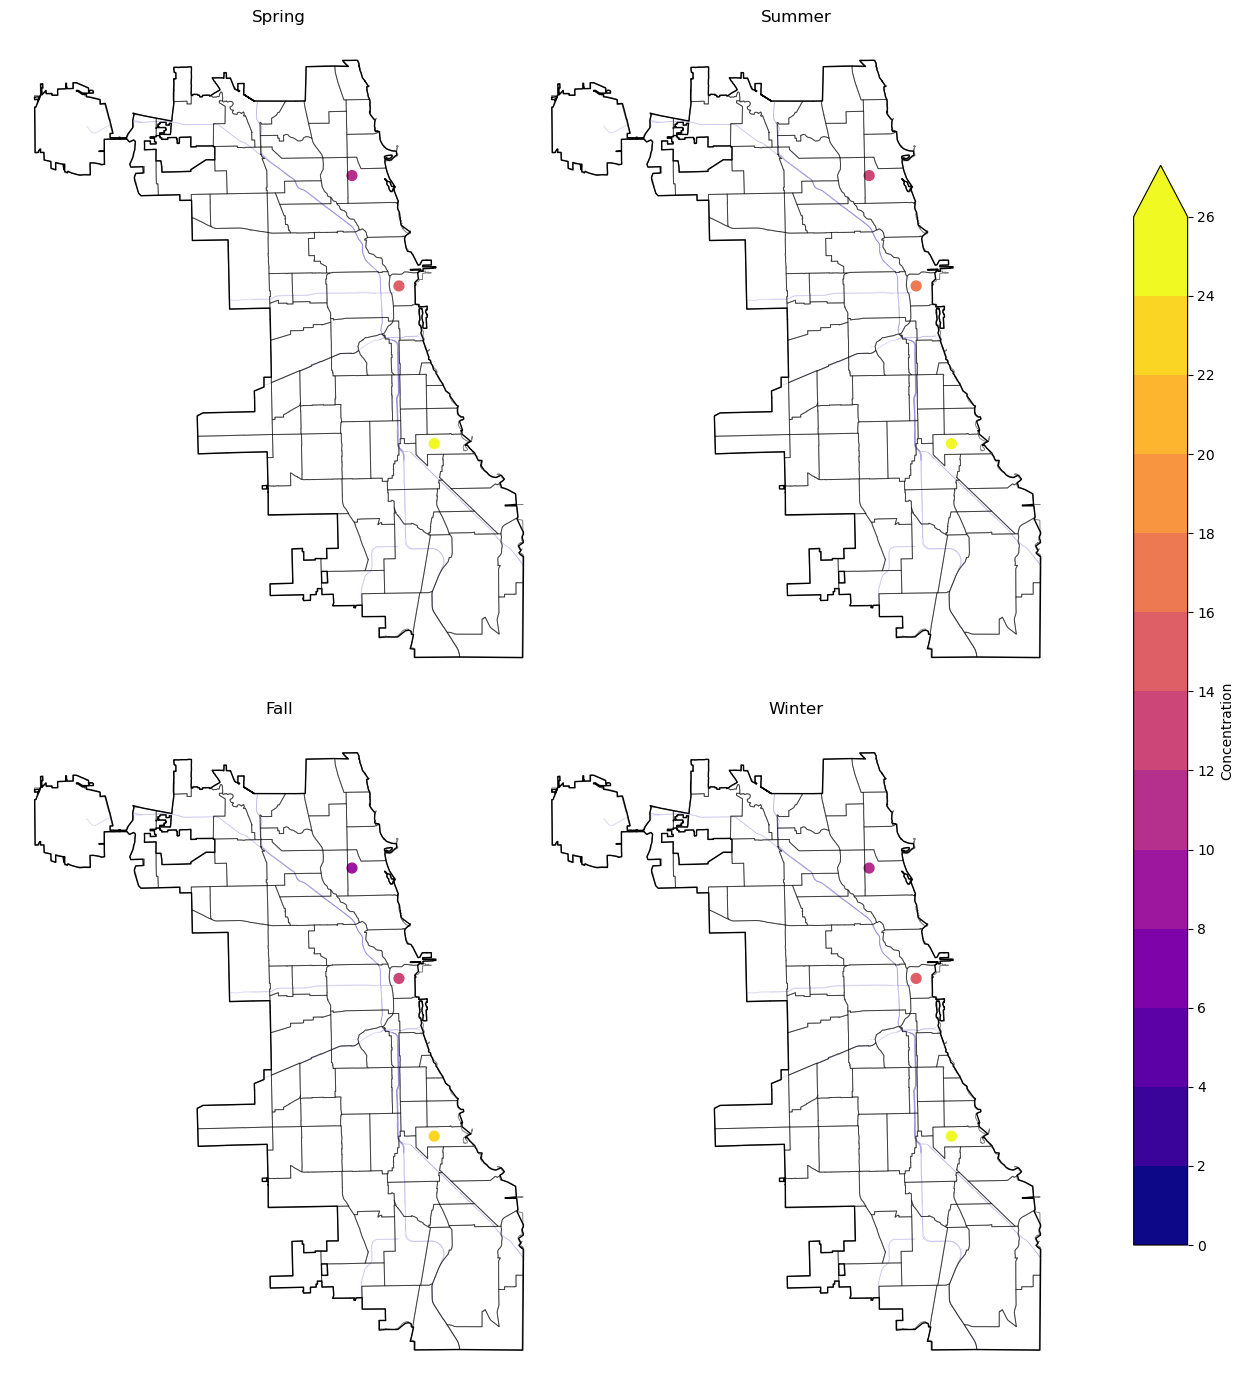

In [48]:
# fake data for each season
data["spring"] = data["concentration"] + 2
data["summer"] = data["concentration"] + 4
data["fall"] = data["concentration"] + 1
data["winter"] = data["concentration"] + 3

# make 4 maps: 2 rows and 2 columns
fig, axes = plt.subplots(2, 2, figsize=(14, 14))

levels = [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26]
cmap = plt.get_cmap("plasma", len(levels) - 1)
norm = BoundaryNorm(levels, cmap.N)

# Spring: top left
ax = axes[0, 0]  # 0,0 is the location of the subplot in the larger figure 
chicago_limits.plot(ax=ax, color="white", edgecolor="black")
chicago_roads.plot(ax=ax, color="slateblue", alpha=0.2, linewidth=0.4)
chicago_communities.boundary.plot(ax=ax, color="k", alpha=0.5, linewidth=0.7)
dots = ax.scatter(data.lon, data.lat, c=data.spring, cmap=cmap, norm=norm, s=50)
ax.set_title("Spring")
ax.set_axis_off()

# Summer: top right
ax = axes[0, 1]
chicago_limits.plot(ax=ax, color="white", edgecolor="black")
chicago_roads.plot(ax=ax, color="slateblue", alpha=0.2, linewidth=0.4)
chicago_communities.boundary.plot(ax=ax, color="k", alpha=0.5, linewidth=0.7)
dots = ax.scatter(data.lon, data.lat, c=data.summer, cmap=cmap, norm=norm, s=50)
ax.set_title("Summer")
ax.set_axis_off()

# Fall: bottom left
ax = axes[1, 0]
chicago_limits.plot(ax=ax, color="white", edgecolor="black")
chicago_roads.plot(ax=ax, color="slateblue", alpha=0.2, linewidth=0.4)
chicago_communities.boundary.plot(ax=ax, color="k", alpha=0.5, linewidth=0.7)
dots = ax.scatter(data.lon, data.lat, c=data.fall, cmap=cmap, norm=norm, s=50)
ax.set_title("Fall")
ax.set_axis_off()

# Winter: bottom right
ax = axes[1, 1]
chicago_limits.plot(ax=ax, color="white", edgecolor="black")
chicago_roads.plot(ax=ax, color="slateblue", alpha=0.2, linewidth=0.4)
chicago_communities.boundary.plot(ax=ax, color="k", alpha=0.5, linewidth=0.7)
dots = ax.scatter(data.lon, data.lat, c=data.winter, cmap=cmap, norm=norm, s=50)
ax.set_title("Winter")
ax.set_axis_off()

fig.tight_layout()
# One colorbar for all 4 maps
fig.colorbar(dots, ax=axes, boundaries=levels, ticks=levels, extend="max", label="Concentration", shrink=0.8)

plt.show()